# pandas 进阶修炼 ｜早起Python

**本习题由公众号【早起Python & 可视化图鉴】 原创，授权「和鲸社区」独家第三方平台发布。**


**转载及其他形式合作请与我们联系，未经授权严禁搬运及二次创作，侵权必究！**



本习题基于 `pandas` 版本 `1.1.3`，所有内容应当在 `Jupyter Notebook` 中执行以获得最佳效果。

不同版本之间写法可能会有少许不同，如若碰到此情况，你应该学会如何自行检索解决。

# 4 - 数据统计描述性分析




在上一章完成基本的数据预览以及缺失值和重复值的处理后。

下一个步骤就是对数据进行简单的统计描述性分析，进一步观察数据特征。

本章就整理了部分常见操作进行练习。

## 初始化



该 `Notebook` 版本为**习题+答案版**


请执行下方单元格以初始化读取本节习题的答案

执行完毕后，你可以使用 `ans(1)` 来查看第 1 题的参考解答，其余习题类似。

注意：所有答案并非固定（唯一），我提供的答案仅供参考（并非推荐答案或者最优解）

如果发现任何错误或者你有更好的解答，可以微信搜索公众号「早起Python」提交以获得奖励！


In [2]:
### 请务必执行本单元格加载本章所需要的数据与答案！
### 本单元格仅需执行一次！
### 由于和鲸社区数据缓存有一定时效，如若在后续的使用过程中出现数据文件不存在的问题，请重新执行本单元格以加载数据
! mkdir data4 > /dev/null 2>&1
! wget http://101.34.9.218:8080/pandas300/data/data4.zip > /dev/null 2>&1
!unzip /home/mw/project/data4.zip -d /home/mw/project/data4 > /dev/null 2>&1

import sys
import os
import pandas as pd
# os.chdir('data4')
from inits import initialize,ans
res = initialize("answer-4.txt")

The system cannot find the path specified.
The system cannot find the path specified.
The system cannot find the path specified.


***************正在初始化***************
*************读取到配置文件*************
***************初始化成功***************


## 加载数据

In [3]:
import pandas as pd
df = pd.read_excel("2020年中国大学排名.xlsx")

## 数据探索

### 1 - 查看数据



查看数据前 10 行

In [3]:
df.head(10)

,排名,学校名称,省市,学校类型,总分,办学层次得分,学科水平得分,办学资源得分,师资规模与结构得分,人才培养得分,科学研究得分,社会服务得分,高端人才得分,重大项目与成果得分,国际竞争力得分
0,1,清华大学,北京,综合,852.5,38.2,72.4,39.6,48.4,256.8,69.1,40.6,76.5,131.0,79.9
1,2,北京大学,北京,综合,746.7,36.1,73.1,24.6,49.2,237.6,71.0,16.2,71.9,105.8,61.2
2,3,浙江大学,浙江,综合,649.2,33.9,65.3,20.1,48.3,215.3,68.6,23.9,49.1,81.7,43.0
3,4,上海交通大学,上海,综合,625.9,35.4,53.6,22.1,43.8,192.8,81.2,18.1,45.8,93.0,40.1
4,5,南京大学,江苏,综合,566.1,35.1,47.8,10.3,47.4,218.6,59.6,5.3,42.0,71.2,29.0
5,6,复旦大学,上海,综合,556.7,36.6,48.4,14.9,46.3,198.5,65.7,6.5,42.9,62.0,34.8
6,7,中国科学技术大学,安徽,理工,526.4,40.0,39.1,10.6,45.9,191.5,52.6,0.2,55.1,49.2,42.2
7,8,华中科技大学,湖北,综合,497.7,31.9,45.2,11.3,44.2,182.8,58.3,22.0,25.5,44.9,31.8
8,9,武汉大学,湖北,综合,488.0,31.7,48.4,9.9,45.3,198.8,51.3,11.8,21.4,44.2,25.2
9,10,中山大学,广东,综合,457.2,30.3,47.1,13.7,46.8,154.4,65.9,5.6,27.1,33.8,32.6


### 2 - 修改索引



数据已经按照降序排列，让 学校 当索引会更好一点

-> 修改索引为 学校名称 列

In [6]:
df.set_index('学校名称')

,排名,省市,学校类型,总分,办学层次得分,学科水平得分,办学资源得分,师资规模与结构得分,人才培养得分,科学研究得分,社会服务得分,高端人才得分,重大项目与成果得分,国际竞争力得分
学校名称,,,,,,,,,,,,,,
清华大学,1,北京,综合,852.5,38.2,72.4,39.6,48.4,256.8,69.1,40.6,76.5,131.0,79.9
北京大学,2,北京,综合,746.7,36.1,73.1,24.6,49.2,237.6,71.0,16.2,71.9,105.8,61.2
浙江大学,3,浙江,综合,649.2,33.9,65.3,20.1,48.3,215.3,68.6,23.9,49.1,81.7,43.0
上海交通大学,4,上海,综合,625.9,35.4,53.6,22.1,43.8,192.8,81.2,18.1,45.8,93.0,40.1
南京大学,5,江苏,综合,566.1,35.1,47.8,10.3,47.4,218.6,59.6,5.3,42.0,71.2,29.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
南京邮电大学,96,江苏,综合,213.9,25.0,12.5,2.4,34.8,101.2,12.4,6.5,1.6,4.6,13.0
河南大学,97,河南,综合,212.9,24.2,22.7,3.4,32.5,97.5,15.7,2.1,1.3,4.2,9.2
上海师范大学,98,上海,师范,212.8,27.3,17.9,3.6,32.1,96.9,14.0,0.5,2.0,6.8,11.8


### 3 - 查看数据量

也就是数据框的 行 * 列，总共单元格的数量

In [9]:
df.shape   # 行和列  元组
df.size
ans(3)

df.size


### 4 - 数据排序



将数据按照总分升序排列，并展示前20个学校

备注：也就是看倒数20名啦

In [16]:
df.sort_values(by='总分').head(20)   # 默认就是升序
# ans(4)
# df.sort_values(by='总分', ascending=True).head(20)

,排名,学校名称,省市,学校类型,总分,办学层次得分,学科水平得分,办学资源得分,师资规模与结构得分,人才培养得分,科学研究得分,社会服务得分,高端人才得分,重大项目与成果得分,国际竞争力得分
99,100,广州大学,广东,综合,211.1,23.2,16.4,5.0,33.7,95.9,14.4,0.6,2.0,5.2,14.8
98,99,杭州电子科技大学,浙江,理工,211.6,25.4,12.6,2.7,36.5,103.4,12.0,2.5,1.5,2.6,12.3
97,98,上海师范大学,上海,师范,212.8,27.3,17.9,3.6,32.1,96.9,14.0,0.5,2.0,6.8,11.8
96,97,河南大学,河南,综合,212.9,24.2,22.7,3.4,32.5,97.5,15.7,2.1,1.3,4.2,9.2
95,96,南京邮电大学,江苏,综合,213.9,25.0,12.5,2.4,34.8,101.2,12.4,6.5,1.6,4.6,13.0
94,95,广东工业大学,广东,理工,214.2,24.2,15.5,3.7,32.6,96.7,13.8,3.2,3.1,5.3,16.2
93,94,湖北大学,湖北,综合,214.5,26.3,14.7,2.3,35.0,105.8,10.5,2.9,1.2,3.7,12.1
92,93,南京信息工程大学,江苏,理工,216.6,23.6,16.1,2.4,33.6,97.5,15.1,4.7,2.1,3.6,18.0
91,92,燕山大学,河北,理工,216.7,26.6,15.2,2.3,34.5,107.2,12.6,2.8,2.5,4.8,8.2
90,91,长安大学,陕西,理工,218.9,27.2,14.0,3.7,34.1,104.9,12.1,12.4,1.1,1.1,8.2


### 5 - 数据排序

将数据按照 高端人才得分 降序排序，展示前 10 位

In [17]:
df.sort_values(by='高端人才得分',ascending=False).head(10)

,排名,学校名称,省市,学校类型,总分,办学层次得分,学科水平得分,办学资源得分,师资规模与结构得分,人才培养得分,科学研究得分,社会服务得分,高端人才得分,重大项目与成果得分,国际竞争力得分
0,1,清华大学,北京,综合,852.5,38.2,72.4,39.6,48.4,256.8,69.1,40.6,76.5,131.0,79.9
1,2,北京大学,北京,综合,746.7,36.1,73.1,24.6,49.2,237.6,71.0,16.2,71.9,105.8,61.2
6,7,中国科学技术大学,安徽,理工,526.4,40.0,39.1,10.6,45.9,191.5,52.6,0.2,55.1,49.2,42.2
2,3,浙江大学,浙江,综合,649.2,33.9,65.3,20.1,48.3,215.3,68.6,23.9,49.1,81.7,43.0
3,4,上海交通大学,上海,综合,625.9,35.4,53.6,22.1,43.8,192.8,81.2,18.1,45.8,93.0,40.1
5,6,复旦大学,上海,综合,556.7,36.6,48.4,14.9,46.3,198.5,65.7,6.5,42.9,62.0,34.8
4,5,南京大学,江苏,综合,566.1,35.1,47.8,10.3,47.4,218.6,59.6,5.3,42.0,71.2,29.0
45,46,南方科技大学,广东,综合,289.0,26.7,7.1,16.9,41.9,105.0,26.4,1.0,38.9,7.1,18.0
9,10,中山大学,广东,综合,457.2,30.3,47.1,13.7,46.8,154.4,65.9,5.6,27.1,33.8,32.6
7,8,华中科技大学,湖北,综合,497.7,31.9,45.2,11.3,44.2,182.8,58.3,22.0,25.5,44.9,31.8


### 6 - 分列排名



查看各项得分最高的学校名称

In [21]:
# 没明白啥意思
df.iloc[:,3:]

,学校类型,总分,办学层次得分,学科水平得分,办学资源得分,师资规模与结构得分,人才培养得分,科学研究得分,社会服务得分,高端人才得分,重大项目与成果得分,国际竞争力得分
0,综合,852.5,38.2,72.4,39.6,48.4,256.8,69.1,40.6,76.5,131.0,79.9
1,综合,746.7,36.1,73.1,24.6,49.2,237.6,71.0,16.2,71.9,105.8,61.2
2,综合,649.2,33.9,65.3,20.1,48.3,215.3,68.6,23.9,49.1,81.7,43.0
3,综合,625.9,35.4,53.6,22.1,43.8,192.8,81.2,18.1,45.8,93.0,40.1
4,综合,566.1,35.1,47.8,10.3,47.4,218.6,59.6,5.3,42.0,71.2,29.0
...,...,...,...,...,...,...,...,...,...,...,...,...
95,综合,213.9,25.0,12.5,2.4,34.8,101.2,12.4,6.5,1.6,4.6,13.0
96,综合,212.9,24.2,22.7,3.4,32.5,97.5,15.7,2.1,1.3,4.2,9.2
97,师范,212.8,27.3,17.9,3.6,32.1,96.9,14.0,0.5,2.0,6.8,11.8
98,理工,211.6,25.4,12.6,2.7,36.5,103.4,12.0,2.5,1.5,2.6,12.3


### 7 - 统计信息｜均值

计算总分列的均值

In [22]:
df['总分'].mean()

322.5

### 8 - 统计信息｜中位数



计算总分列的中位数

In [25]:
df['总分'].median()
ans(8)

df.总分.median()


### 9 - 统计信息｜众数


计算总分列的众数

### 10 -统计信息｜部分

计算 总分、高端人才得分、办学层次得分的最大最小值、中位数、均值

In [26]:
ans(10)
# 统计多个列的 多个特性：最大  最小 均值
df.agg({
        "总分": ["min", "max", "median", "mean"],
        "高端人才得分": ["min", "max", "median", "mean"],
        "办学层次得分":["min", "max", "median", "mean"]})

df.agg({
        "总分": ["min", "max", "median", "mean"],
        "高端人才得分": ["min", "max", "median", "mean"],
        "办学层次得分":["min", "max", "median", "mean"]})


,总分,高端人才得分,办学层次得分
min,211.10,0.800,23.200
max,852.50,76.500,40.000
median,279.65,6.150,29.400
mean,322.50,11.176,29.692


### 11 - 统计信息｜完整



查看数值型数据的统计信息（均值、分位数等），并保留两位小数

In [8]:
ans(11)
df.describe().round(2)

df.describe().round(2).T


,排名,总分,办学层次得分,学科水平得分,办学资源得分,师资规模与结构得分,人才培养得分,科学研究得分,社会服务得分,高端人才得分,重大项目与成果得分,国际竞争力得分
count,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00
mean,50.49,322.50,29.69,27.49,7.19,39.03,134.41,26.87,7.47,11.18,20.37,18.80
std,29.00,118.36,3.31,12.42,5.51,4.75,33.82,15.61,7.99,14.14,22.02,10.56
min,1.00,211.10,23.20,6.80,2.30,28.70,91.80,9.70,0.00,0.80,1.10,8.20
25%,25.75,244.18,27.30,19.65,3.98,35.98,109.08,15.68,2.20,3.08,7.48,12.70
50%,50.50,279.65,29.40,24.00,5.25,37.95,122.80,21.85,5.20,6.15,13.75,15.60
75%,75.25,378.80,31.90,33.92,9.02,43.20,154.75,32.72,9.80,12.35,24.78,21.00
max,100.00,852.50,40.00,73.10,39.60,49.20,256.80,81.20,40.60,76.50,131.00,79.90


### 12 - 统计信息｜分组

计算各省市总分均值

In [13]:
df.groupby('省市')['总分'].mean()


省市
上海     350.510000
云南     234.100000
北京     362.827778
吉林     326.000000
四川     349.266667
天津     396.200000
安徽     328.700000
山东     304.633333
广东     286.011111
江苏     298.386667
江西     228.400000
河北     216.700000
河南     223.900000
浙江     335.150000
湖北     335.085714
湖南     320.100000
甘肃     300.400000
福建     313.550000
辽宁     339.550000
重庆     289.200000
陕西     297.685714
黑龙江    364.800000
Name: 总分, dtype: float64

### 13 - 统计信息｜相关系数



也就是相关系数矩阵，也就是每两列之间的相关性系数

In [14]:
ans(13)

df.corr() 


### 14 - 相关系数｜热力图



将上一题的相关性系数矩阵制作为热力图

微信搜索公众号「早起Python」，关注后可以获得更多资源！

In [15]:
ans(14)

### 方法一 ###

df.corr().style.background_gradient(cmap='coolwarm').set_precision(2)

### 方法二 ###

借助 `matplotlib` 和 `seaborn` 

其中中文设置可以参考我的这篇文章 https://mp.weixin.qq.com/s/WKOGvQP-6QUAP00ZXjhweg

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize = (9,6),dpi=100)
sns.set(font='Songti SC')
sns.heatmap(df.corr().round(2),annot=True,cmap='RdBu')
plt.show()


### 15 - 统计信息｜频率

计算各省市出现的次数

In [27]:
ans(15)
df['省市'].value_counts()
type(df.省市.value_counts())  # pandas.core.series.Series
# 
df.省市.value_counts()

df.省市.value_counts()


北京     18
江苏     15
上海     10
广东      9
湖北      7
陕西      7
浙江      4
四川      3
湖南      3
山东      3
安徽      3
天津      2
黑龙江     2
福建      2
吉林      2
辽宁      2
重庆      2
河南      2
甘肃      1
云南      1
江西      1
河北      1
Name: 省市, dtype: int64

### 16 - 统计信息｜热力地图

结合 `pyecharts` 将各省市高校上榜数量进行地图可视化

In [25]:
list(pd.DataFrame(df.省市.value_counts()).index)  # 得到省市名字的列表
list(pd.DataFrame(df.省市.value_counts()).省市)   # 得到省市出现次数的列表
# ans(16)


[18, 15, 10, 9, 7, 7, 4, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1]

### 17 - 统计信息｜直方图

绘制总分的直方图、密度估计图

import seaborn as sns
sns.set(font='Songti SC')
sns.distplot(df['总分'])


<AxesSubplot:xlabel='总分', ylabel='Count'>

c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\IPython\core\events.py:89: UserWarning: Glyph 24635 (\N{CJK UNIFIED IDEOGRAPH-603B}) missing from current font.
  func(*args, **kwargs)
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\IPython\core\events.py:89: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from current font.
  func(*args, **kwargs)
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\IPython\core\pylabtools.py:151: UserWarning: Glyph 24635 (\N{CJK UNIFIED IDEOGRAPH-603B}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\IPython\core\pylabtools.py:151: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


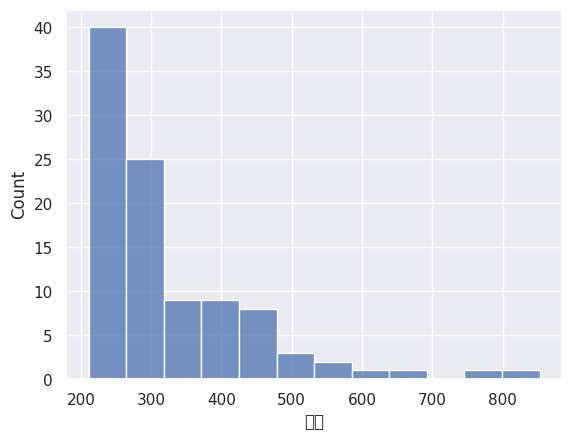

In [33]:
ans(17)
import seaborn as sns
sns.set(font='Songti SC')
sns.distplot(df['总分'])

![公众号：早起Python](http://liuzaoqi.oss-cn-beijing.aliyuncs.com/2021/09/18/16319660121648.jpg?域名/sample.jpg?x-oss-process=style/stylename)

## 2 个 pandas EDA 插件

在 pandas 之外，还有两个插件可以快速实现 EDA

下面不作为习题，仅供介绍，感兴趣可以进一步搜索了解

执行全部代码即可获得 EDA 报告！

### 18 - pandas_profiling



如果没有提前安装 `pandas_profiling` 的话，需要提前 `pip` 进行安装

In [ ]:
! pip install pandas_profiling

In [35]:
import pandas_profiling

In [37]:
# xiaozhan  后面添加了 to_file直接保存到html文件  看自己需求
pandas_profiling.ProfileReport(df).to_file(output_file='profile.html')

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 25490 (\N{CJK UNIFIED IDEOGRAPH-6392}) missing from current font.
  plt.savefig(
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 21517 (\N{CJK UNIFIED IDEOGRAPH-540D}) missing from current font.
  plt.savefig(
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 24635 (\N{CJK UNIFIED IDEOGRAPH-603B}) missing from current font.
  plt.savefig(
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from current font.
  plt.savefig(
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 25490 

c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 31185 (\N{CJK UNIFIED IDEOGRAPH-79D1}) missing from current font.
  plt.savefig(
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 23398 (\N{CJK UNIFIED IDEOGRAPH-5B66}) missing from current font.
  plt.savefig(
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 30740 (\N{CJK UNIFIED IDEOGRAPH-7814}) missing from current font.
  plt.savefig(
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 31350 (\N{CJK UNIFIED IDEOGRAPH-7A76}) missing from current font.
  plt.savefig(
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 24471 

c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 25490 (\N{CJK UNIFIED IDEOGRAPH-6392}) missing from current font.
  plt.savefig(
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 21517 (\N{CJK UNIFIED IDEOGRAPH-540D}) missing from current font.
  plt.savefig(
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 24635 (\N{CJK UNIFIED IDEOGRAPH-603B}) missing from current font.
  plt.savefig(
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from current font.
  plt.savefig(
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 24635 

c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 31038 (\N{CJK UNIFIED IDEOGRAPH-793E}) missing from current font.
  plt.savefig(
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 20250 (\N{CJK UNIFIED IDEOGRAPH-4F1A}) missing from current font.
  plt.savefig(
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 26381 (\N{CJK UNIFIED IDEOGRAPH-670D}) missing from current font.
  plt.savefig(
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 21153 (\N{CJK UNIFIED IDEOGRAPH-52A1}) missing from current font.
  plt.savefig(
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 24471 

...

c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 32508 (\N{CJK UNIFIED IDEOGRAPH-7EFC}) missing from current font.
  plt.savefig(
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 21512 (\N{CJK UNIFIED IDEOGRAPH-5408}) missing from current font.
  plt.savefig(
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 29702 (\N{CJK UNIFIED IDEOGRAPH-7406}) missing from current font.
  plt.savefig(
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 24037 (\N{CJK UNIFIED IDEOGRAPH-5DE5}) missing from current font.
  plt.savefig(
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 24072 

c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 25490 (\N{CJK UNIFIED IDEOGRAPH-6392}) missing from current font.
  plt.savefig(
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 21517 (\N{CJK UNIFIED IDEOGRAPH-540D}) missing from current font.
  plt.savefig(
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 24635 (\N{CJK UNIFIED IDEOGRAPH-603B}) missing from current font.
  plt.savefig(
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from current font.
  plt.savefig(
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 21150 

c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 23398 (\N{CJK UNIFIED IDEOGRAPH-5B66}) missing from current font.
  plt.savefig(
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 26657 (\N{CJK UNIFIED IDEOGRAPH-6821}) missing from current font.
  plt.savefig(
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 31867 (\N{CJK UNIFIED IDEOGRAPH-7C7B}) missing from current font.
  plt.savefig(
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 22411 (\N{CJK UNIFIED IDEOGRAPH-578B}) missing from current font.
  plt.savefig(
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\pandas_profiling\visualisation\utils.py:73: UserWarning: Glyph 30465 

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

### 19 - sweetviz

如果没有提前安装 `sweetviz` 的话，需要提前 `pip` 进行安装

In [ ]:
! pip install sweetviz

In [40]:
import sweetviz as sv

report = sv.analyze(df)
report.show_html(filepath='sweet_report.html')

                                             |                                             | [  0%]   00:00 ->…

c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\sweetviz\graph.py:33: UserWarning: Glyph 24191 (\N{CJK UNIFIED IDEOGRAPH-5E7F}) missing from current font.
  figure.savefig(as_raw_bytes, format='png', transparent=True)
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\sweetviz\graph.py:33: UserWarning: Glyph 19996 (\N{CJK UNIFIED IDEOGRAPH-4E1C}) missing from current font.
  figure.savefig(as_raw_bytes, format='png', transparent=True)
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\sweetviz\graph.py:33: UserWarning: Glyph 19978 (\N{CJK UNIFIED IDEOGRAPH-4E0A}) missing from current font.
  figure.savefig(as_raw_bytes, format='png', transparent=True)
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\sweetviz\graph.py:33: UserWarning: Glyph 28023 (\N{CJK UNIFIED IDEOGRAPH-6D77}) missing from current font.
  figure.savefig(as_raw_bytes, format='png', transparent=True)
c:\users\xli3\appdata\local\programs

c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\sweetviz\graph.py:33: UserWarning: Glyph 26519 (\N{CJK UNIFIED IDEOGRAPH-6797}) missing from current font.
  figure.savefig(as_raw_bytes, format='png', transparent=True)
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\sweetviz\graph.py:33: UserWarning: Glyph 19994 (\N{CJK UNIFIED IDEOGRAPH-4E1A}) missing from current font.
  figure.savefig(as_raw_bytes, format='png', transparent=True)
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\sweetviz\graph.py:33: UserWarning: Glyph 20892 (\N{CJK UNIFIED IDEOGRAPH-519C}) missing from current font.
  figure.savefig(as_raw_bytes, format='png', transparent=True)
c:\users\xli3\appdata\local\programs\python\python38\lib\site-packages\sweetviz\graph.py:33: UserWarning: Glyph 24072 (\N{CJK UNIFIED IDEOGRAPH-5E08}) missing from current font.
  figure.savefig(as_raw_bytes, format='png', transparent=True)
c:\users\xli3\appdata\local\programs

Report sweet_report.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.


执行完上面的代码后，当前目录下会出现一个html文件，打开即可看到相关 EDA 报告

![](http://liuzaoqi.oss-cn-beijing.aliyuncs.com/2021/09/16/16317972442543.jpg?域名/sample.jpg?x-oss-process=style/stylename)